# 03: Preliminary Regularized Regression

First model on the county-year dataset built in `02_eda.ipynb`. Ridge, Lasso and Elastic Net, compared against simple baselines on held-out later years.

- **Response:** `log1p(slf_obs)`, the lanternfly count per county-year, with `log(all_obs)` (observer effort) as a predictor rather than dividing it out (see section 2).
- **Scope:** invasion region (same box as the EDA maps), county-years with ≥200 iNaturalist observations.
- **Feature sets:** **A** = effort + climate + location; **B** = A + last year's lanternfly count (README Open Decision 6: spread vs. environment).

 *Code generated w/ help from Claude Code* See `docs/ai_usage.md` for how it was checked.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

YEARS = list(range(2014, 2026))      # 2026 excluded: partial year
TRAIN_YEARS = list(range(2015, 2023))  # 2014 has no prior year for the lag feature
TEST_YEARS = [2023, 2024, 2025]
REGION = dict(lon=(-92, -66), lat=(33, 46))  # same box as the EDA maps
MIN_OBS = 200                                 # same effort cutoff as EDA 1c

## 1. Build the modeling table

One row per county-year. Sources:
- `county_year_effort.parquet` (saved by `02_eda.ipynb`): all iNaturalist observations (effort) and lanternfly observations from GBIF.
- `climate_county_month.parquet` (saved by `01_data_loading.ipynb`): NOAA nClimDiv monthly county climate, aggregated to the year:
  - `tavg_annual`: mean monthly average temperature (°F), all 12 months required
  - `tmin_winter`: coldest monthly minimum over Dec (previous year) – Feb, all 3 months required
  - `tmax_summer`: mean monthly max temperature, Jun–Aug
  - `precip_annual`: total precipitation (in), all 12 months required
- County centroids (Census 2020 boundaries) for latitude and longitude.
- `lag_log_count`: last year's `log1p(slf_obs)` in the same county. A county-year missing from GBIF had no observations at all, so its lag is 0.

In [2]:
cy = pd.read_parquet(ds.PROCESSED / "county_year_effort.parquet")
cy = cy[cy["year"].isin(YEARS)]
clim = pd.read_parquet(ds.PROCESSED / "climate_county_month.parquet")

# Annual climate summaries; min_count/size checks drop years with missing months.
g = clim.groupby(["fips", "year"])
annual = pd.DataFrame({
    "tavg_annual": g["tavg_f"].mean().where(g["tavg_f"].count() == 12),
    "precip_annual": g["precip_in"].sum(min_count=12),
})
summer = clim[clim["month"].isin([6, 7, 8])].groupby(["fips", "year"])["tmax_f"]
annual["tmax_summer"] = summer.mean().where(summer.count() == 3)
# Winter that ends in year Y = Dec of Y-1 plus Jan-Feb of Y.
w = clim[clim["month"].isin([12, 1, 2])].assign(year=lambda d: d["year"] + (d["month"] == 12))
wg = w.groupby(["fips", "year"])["tmin_f"]
annual["tmin_winter"] = wg.min().where(wg.count() == 3)
annual = annual.reset_index()

# County centroids: compute in an equal-area projection, report in lon/lat.
counties = ds.load_counties()
cent = counties.to_crs(5070).geometry.centroid.to_crs(4326)
centroids = pd.DataFrame({"fips": counties["fips"], "lon": cent.x, "lat": cent.y})

# Last year's lanternfly count, from the full (unfiltered) table.
lag = cy[["fips", "year", "slf_obs"]].assign(year=lambda d: d["year"] + 1)
lag["lag_log_count"] = np.log1p(lag.pop("slf_obs"))

df = (cy.merge(centroids, on="fips", how="left")
        .merge(annual, on=["fips", "year"], how="left")
        .merge(lag, on=["fips", "year"], how="left")
        .fillna({"lag_log_count": 0}))
df["log_effort"] = np.log(df["all_obs"])
df["y"] = np.log1p(df["slf_obs"])

steps = [("all county-years 2014-2025", len(df))]
df = df[df["lon"].between(*REGION["lon"]) & df["lat"].between(*REGION["lat"])]
steps.append(("in invasion region box", len(df)))
df = df[df["all_obs"] >= MIN_OBS]
steps.append((f"with >= {MIN_OBS} observations", len(df)))
CLIMATE = ["tavg_annual", "tmin_winter", "tmax_summer", "precip_annual"]
dropped = df[df[CLIMATE].isna().any(axis=1)]
df = df.dropna(subset=CLIMATE)
steps.append(("with complete climate", len(df)))
df = df[df["year"].isin(TRAIN_YEARS + TEST_YEARS)].sort_values(["year", "fips"]).reset_index(drop=True)
steps.append(("in train + test years (2015-2025)", len(df)))

display(pd.DataFrame(steps, columns=["step", "rows"]))
print(f"Dropped for missing climate: {len(dropped)} rows from",
      sorted((dropped["county"] + ", " + dropped["state"]).unique()))

,step,rows
0,all county-years 2014-2025,35827
1,in invasion region box,16811
2,with >= 200 observations,8956
3,with complete climate,8941
4,in train + test years (2015-2025),8790


Dropped for missing climate: 15 rows from ['District of Columbia, DC', 'Lexington, VA']


## 2. Response check: rate or count + effort?

**Question:** Should the response be the lanternfly *rate* (per 10k observations) or the *count* with effort as a predictor?

Dividing by effort assumes sightings grow one-for-one with effort, which is a log-log slope of 1. EDA 1b measured that slope. Below: the same calculation as EDA 1b, then the same check on this modeling table.

In [3]:
def loglog_slope(d):
    d = d[d["slf_obs"] > 0]
    x, y = np.log(d["all_obs"]), np.log(d["slf_obs"])
    return np.polyfit(x, y, 1)[0], np.corrcoef(x, y)[0, 1], len(d)

ever = cy.groupby("fips")["slf_obs"].transform("sum") > 0
for name, d in [("EDA 1b definition (ever-invaded, all US)", cy[ever]), ("this modeling table", df)]:
    s, r, n = loglog_slope(d)
    print(f"{name:42s} slope = {s:.2f}, r = {r:.2f}, n = {n:,}")

EDA 1b definition (ever-invaded, all US)   slope = 0.51, r = 0.39, n = 1,080
this modeling table                        slope = 0.57, r = 0.38, n = 1,044


Share of county-years with zero lanternfly observations: 88.1%
               skew
rate          14.98
count         17.72
log1p(count)   3.62


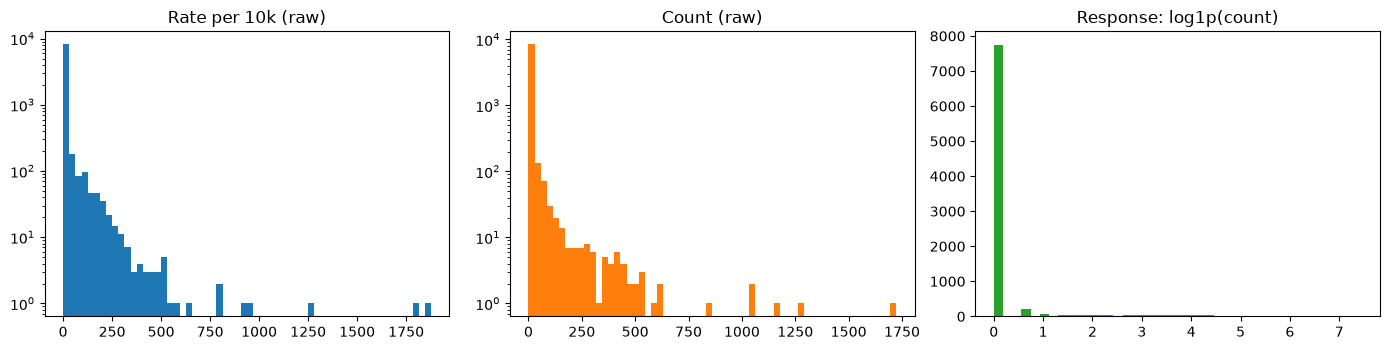

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(df["slf_per_10k"], bins=60); ax[0].set(title="Rate per 10k (raw)", yscale="log")
ax[1].hist(df["slf_obs"], bins=60, color="C1"); ax[1].set(title="Count (raw)", yscale="log")
ax[2].hist(df["y"], bins=40, color="C2"); ax[2].set(title="Response: log1p(count)")
plt.tight_layout()

print(f"Share of county-years with zero lanternfly observations: {(df['slf_obs'] == 0).mean():.1%}")
print(pd.DataFrame({"skew": [df["slf_per_10k"].skew(), df["slf_obs"].skew(), df["y"].skew()]},
                   index=["rate", "count", "log1p(count)"]).round(2))

**Known limitation:** the large spike at zero remains after the log. A linear model can't produce that spike, so a two-part or count model (Poisson / negative binomial) is a natural next comparison.

**Team interpretation:** _TODO_

## 3. Predictor correlation

**Question:** How correlated are the predictors? Strong correlation among the climate variables makes ordinary least squares coefficients unstable, which is the reason for using regularization (also EDA ToDo item 5).

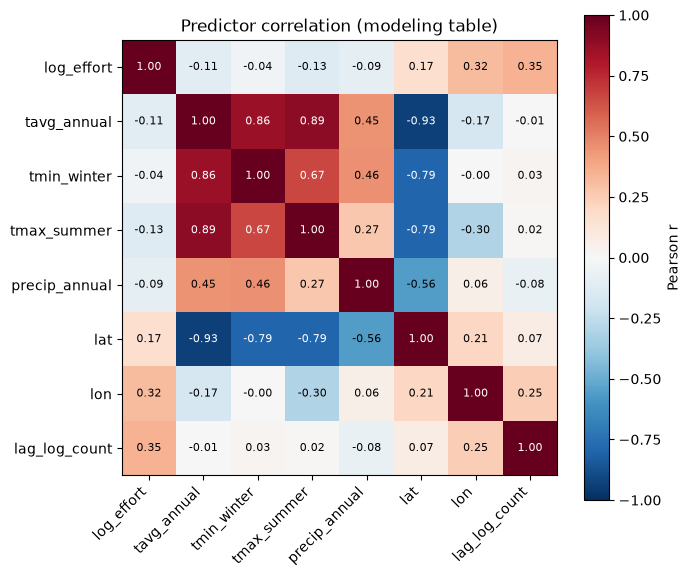

In [5]:
FEATURES_A = ["log_effort", "tavg_annual", "tmin_winter", "tmax_summer", "precip_annual", "lat", "lon"]
FEATURES_B = FEATURES_A + ["lag_log_count"]

corr = df[FEATURES_B].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > .6 else "black")
plt.colorbar(im, label="Pearson r"); ax.set_title("Predictor correlation (modeling table)")
plt.tight_layout()

**Team interpretation:** _TODO_

## 4. Validation design

- **Temporal holdout:** train on 2015–2022, test on 2023–2025. This matches the use case (predicting later years) and the README's methodology principles.
- **Choosing the penalty:** expanding-window CV inside the training years. For each validation year 2019–2022, fit on all earlier training years and score on that year.
- **Scaling:** predictors are standardized inside each pipeline, fit on the training years only, so the test years never inform the scaling. Within the CV folds the scaler is fit on all training years, a small leak that affects only the choice of alpha.

In [6]:
train = df[df["year"].isin(TRAIN_YEARS)].reset_index(drop=True)
test = df[df["year"].isin(TEST_YEARS)].reset_index(drop=True)
assert set(train["year"]).isdisjoint(test["year"])
assert not df[FEATURES_B + ["y"]].isna().any().any()

CV_SPLITS = [(np.flatnonzero(train["year"] < v), np.flatnonzero(train["year"] == v)) for v in range(2019, 2023)]
print(f"train: {len(train):,} rows ({train['year'].min()}-{train['year'].max()}), "
      f"test: {len(test):,} rows ({test['year'].min()}-{test['year'].max()})")
for tr, va in CV_SPLITS:
    print(f"  CV fold: fit {train['year'].iloc[tr].min()}-{train['year'].iloc[tr].max()} ({len(tr):,}), "
          f"validate {train['year'].iloc[va].iloc[0]} ({len(va):,})")

train: 5,309 rows (2015-2022), test: 3,481 rows (2023-2025)
  CV fold: fit 2015-2018 (1,433), validate 2019 (789)
  CV fold: fit 2015-2019 (2,222), validate 2020 (965)
  CV fold: fit 2015-2020 (3,187), validate 2021 (1,041)
  CV fold: fit 2015-2021 (4,228), validate 2022 (1,081)


## 5. Models

For each feature set (A, B): Ridge (L2), Lasso (L1) and Elastic Net (mix), each choosing its penalty with the CV above.

Baselines:
- **Training mean:** predict the average training response everywhere.
- **Effort only:** OLS on `log_effort` alone, showing how much climate and location add beyond effort.
- **Persistence:** predict last year's value (`lag_log_count`), the baseline feature set B has to beat.

In [7]:
ALPHAS = np.logspace(-6, 3, 80)

def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS, cv=CV_SPLITS)),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=ALPHAS, cv=CV_SPLITS, max_iter=50_000)),
        "ElasticNet": make_pipeline(StandardScaler(), ElasticNetCV(alphas=ALPHAS, l1_ratio=[.1, .5, .9],
                                                                   cv=CV_SPLITS, max_iter=50_000)),
    }

def scores(y_true, y_pred):
    return {"test_RMSE": mean_squared_error(y_true, y_pred) ** .5,
            "test_MAE": mean_absolute_error(y_true, y_pred),
            "test_R2": r2_score(y_true, y_pred)}

rows, fitted, preds = [], {}, {}
ytr, yte = train["y"], test["y"]

preds["Baseline: training mean"] = np.full(len(test), ytr.mean())
effort_only = LinearRegression().fit(train[["log_effort"]], ytr)
preds["Baseline: effort only (OLS)"] = effort_only.predict(test[["log_effort"]])
preds["Baseline: persistence"] = test["lag_log_count"].to_numpy()
for name, p in preds.items():
    rows.append({"model": name, "features": "-", **scores(yte, p)})

for fs_name, feats in [("A", FEATURES_A), ("B", FEATURES_B)]:
    for m_name, model in make_models().items():
        model.fit(train[feats], ytr)
        est = model[-1]
        key = f"{m_name} ({fs_name})"
        fitted[key], preds[key] = (model, feats), model.predict(test[feats])
        rows.append({"model": m_name, "features": fs_name, **scores(yte, preds[key]),
                     "alpha": est.alpha_, "l1_ratio": getattr(est, "l1_ratio_", None),
                     "alpha_at_grid_edge": est.alpha_ in (ALPHAS[0], ALPHAS[-1])})

results = pd.DataFrame(rows)
results.style.format({"test_RMSE": "{:.4f}", "test_MAE": "{:.4f}", "test_R2": "{:.4f}",
                      "alpha": "{:.3g}", "l1_ratio": "{:.1f}"}, na_rep="-")

,model,features,test_RMSE,test_MAE,test_R2,alpha,l1_ratio,alpha_at_grid_edge
0,Baseline: training mean,-,1.3509,0.6428,-0.0965,-,-,-
1,Baseline: effort only (OLS),-,1.2419,0.6386,0.0733,-,-,-
2,Baseline: persistence,-,0.5560,0.2142,0.8143,-,-,-
3,Ridge,A,1.2294,0.6152,0.0919,1e-06,-,True
4,Lasso,A,1.2294,0.6152,0.0919,1e-06,-,True
5,ElasticNet,A,1.2294,0.6152,0.0919,1e-06,0.1,True
6,Ridge,B,0.5283,0.2523,0.8323,19.5,-,False
7,Lasso,B,0.5258,0.2512,0.8339,0.0126,-,False
8,ElasticNet,B,0.5248,0.2513,0.8345,0.0213,0.1,False


**Reading `alpha_at_grid_edge`:** if the chosen alpha sits at the *small* end of the grid (1e-6), CV found no benefit from penalizing that feature set, and the fit is effectively ordinary least squares. The grid already runs down to 1e-6.

**Effort coefficient vs. the EDA slope.** Converting the standardized `log_effort` coefficient back to original units gives the change in `log1p(slf_obs)` per one-unit change in `log(all_obs)`. It isn't the same quantity as the EDA 1b slope, which uses only county-years with at least one sighting and has no other predictors, so the two are only roughly comparable.

In [8]:
print(f"Effort-only OLS slope: {effort_only.coef_[0]:.3f}")
for key, (model, feats) in fitted.items():
    i = feats.index("log_effort")
    print(f"{key:18s} log_effort coefficient (original units): {model[-1].coef_[i] / model[0].scale_[i]:.3f}")

Effort-only OLS slope: 0.193
Ridge (A)          log_effort coefficient (original units): 0.151
Lasso (A)          log_effort coefficient (original units): 0.151
ElasticNet (A)     log_effort coefficient (original units): 0.151
Ridge (B)          log_effort coefficient (original units): 0.047
Lasso (B)          log_effort coefficient (original units): 0.043
ElasticNet (B)     log_effort coefficient (original units): 0.048


**Team interpretation:** _TODO_

## 6. Coefficients

Standardized coefficients: the change in `log1p(slf_obs)` per one standard deviation of each predictor, so magnitudes are comparable across predictors. Lasso coefficients of exactly 0 are dropped features.

,Ridge (A),Lasso (A),ElasticNet (A),Ridge (B),Lasso (B),ElasticNet (B)
log_effort,0.169,0.169,0.169,0.052,0.048,0.053
tavg_annual,-0.148,-0.148,-0.148,-0.019,0.000,-0.000
tmin_winter,0.037,0.037,0.037,0.026,0.000,0.011
tmax_summer,0.288,0.288,0.288,0.068,0.007,0.046
precip_annual,0.064,0.064,0.064,0.018,-0.000,0.009
lat,0.139,0.139,0.139,0.065,0.000,0.046
lon,0.138,0.138,0.138,0.039,0.027,0.038
lag_log_count,NaN,NaN,NaN,0.605,0.603,0.595


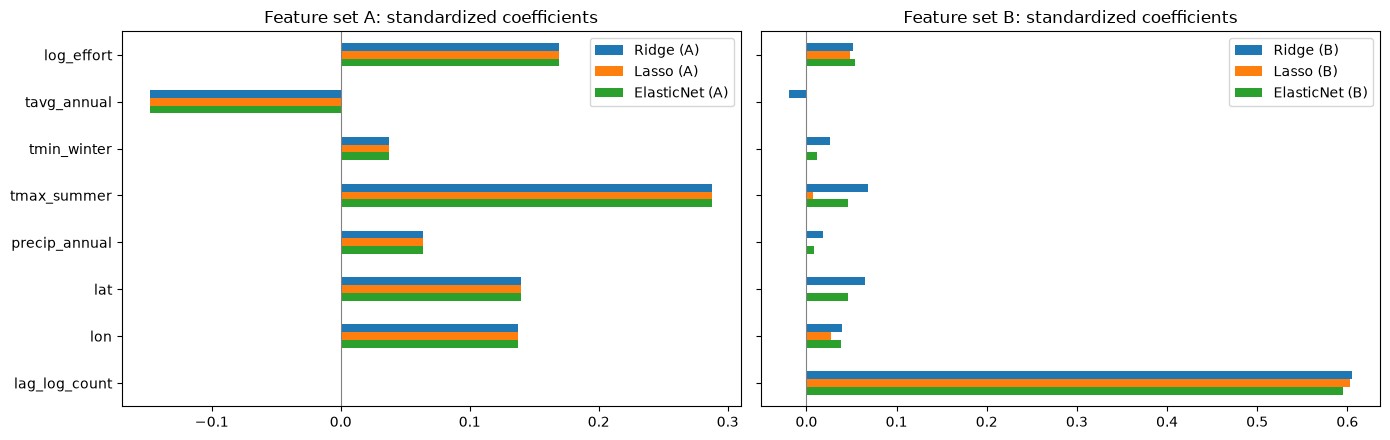

In [9]:
coefs = pd.DataFrame({key: pd.Series(model[-1].coef_, index=feats) for key, (model, feats) in fitted.items()})
coefs = coefs.reindex(FEATURES_B)
display(coefs.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, fs in zip(ax, ["A", "B"]):
    cols = [c for c in coefs.columns if c.endswith(f"({fs})")]
    coefs[cols].plot.barh(ax=a)
    a.axvline(0, color="grey", lw=.8); a.set_title(f"Feature set {fs}: standardized coefficients")
    a.invert_yaxis()
plt.tight_layout()

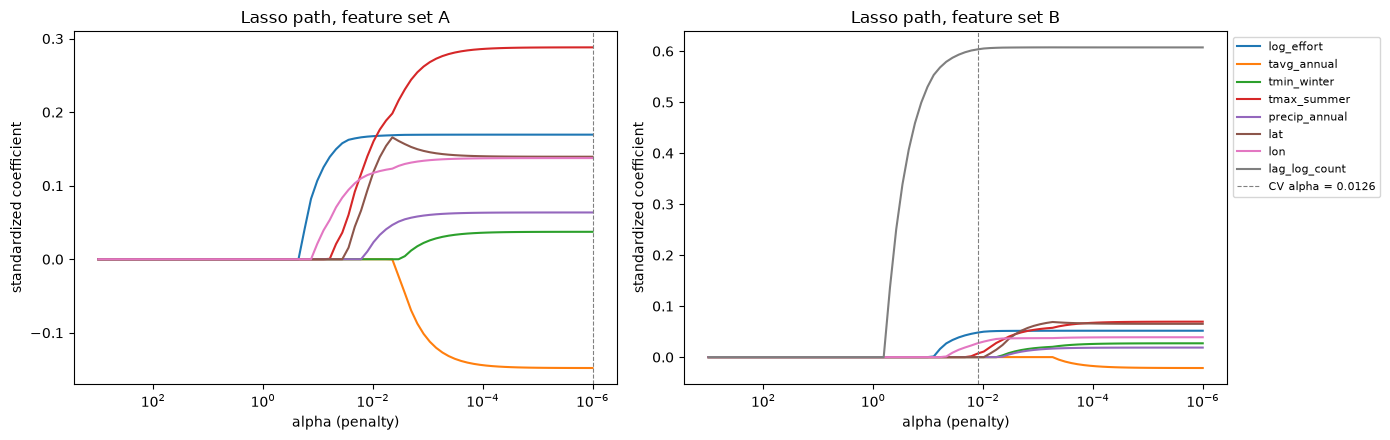

In [10]:
# Lasso path: as the penalty shrinks (left to right), which predictors enter first?
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (fs, feats) in zip(ax, [("A", FEATURES_A), ("B", FEATURES_B)]):
    X = StandardScaler().fit_transform(train[feats])
    alphas, path, _ = lasso_path(X, ytr - ytr.mean(), alphas=ALPHAS[::-1], max_iter=50_000)
    for k, f in enumerate(feats):
        a.plot(alphas, path[k], label=f)
    chosen = fitted[f"Lasso ({fs})"][0][-1].alpha_
    a.axvline(chosen, color="grey", ls="--", lw=.8, label=f"CV alpha = {chosen:.3g}")
    a.set(xscale="log", xlabel="alpha (penalty)", ylabel="standardized coefficient",
          title=f"Lasso path, feature set {fs}")
    a.invert_xaxis()
ax[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()

**Team interpretation:** _TODO_

## 7. Diagnostics (best regularized model on the test years)

**Question:** Where does the best model miss? Plots of predicted vs. actual and residuals vs. fitted, then test error by state.

Best regularized model by test RMSE: ElasticNet (B) (RMSE = 0.525)


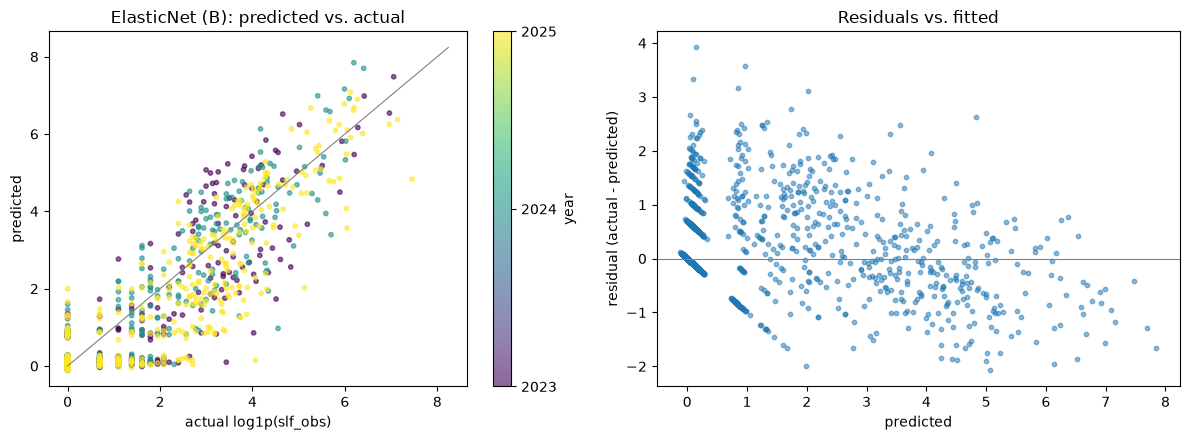

In [11]:
reg = results[results["features"] != "-"]
best = reg.loc[reg["test_RMSE"].idxmin()]
best_key = f"{best['model']} ({best['features']})"
p = preds[best_key]
resid = yte - p
print(f"Best regularized model by test RMSE: {best_key} (RMSE = {best['test_RMSE']:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc = ax[0].scatter(yte, p, c=test["year"], s=10, alpha=.6, cmap="viridis")
lim = [0, max(yte.max(), p.max()) * 1.05]
ax[0].plot(lim, lim, color="grey", lw=.8)
ax[0].set(xlabel="actual log1p(slf_obs)", ylabel="predicted", title=f"{best_key}: predicted vs. actual")
plt.colorbar(sc, ax=ax[0], label="year", ticks=TEST_YEARS, format="%d")
ax[1].scatter(p, resid, s=10, alpha=.5)
ax[1].axhline(0, color="grey", lw=.8)
ax[1].set(xlabel="predicted", ylabel="residual (actual - predicted)", title="Residuals vs. fitted")
plt.tight_layout()

In [12]:
by_state = (test.assign(sq_err=resid ** 2, resid=resid)
                .groupby("state")
                .agg(n=("y", "size"), RMSE=("sq_err", lambda s: s.mean() ** .5), mean_resid=("resid", "mean"))
                .sort_values("n", ascending=False))
by_state.round(3)

,n,RMSE,mean_resid
state,,,
VA,350,0.861,0.328
NC,279,0.316,-0.032
OH,259,0.572,0.190
TN,228,0.212,0.007
IL,201,0.190,-0.007
PA,200,0.844,0.018
MI,199,0.267,-0.010
KY,195,0.274,0.022
NY,186,0.636,-0.007


**Team interpretation:** _TODO_

---

## ToDo
### Modeling / Interpretation

- Does climate add anything beyond effort (compare with the effort-only baseline)? Does it hold up once last year's count is included (A vs. B)?
- Which predictors does Lasso drop, and does that agree with the correlation heatmap?
- **Next comparisons:** regularized Poisson / negative binomial on `slf_obs` with log effort; a two-part model for the zeros; a spatial holdout (hold out states) alongside the temporal one.
- Candidate features not included yet: host plants (EDA item 9), neighbor-county lanternfly counts, year / time since first detection.